In [ ]:
# Core libraries
import numpy as np
import pandas as pd
from itertools import combinations

# Plotting
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, FuncFormatter
import seaborn as sns
import plotly.graph_objects as go
from IPython.display import clear_output

# Modeling and stats
from scipy.optimize import curve_fit
from scipy.integrate import simpson
from scipy.stats import friedmanchisquare, wilcoxon, mannwhitneyu
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.anova import AnovaRM

In [ ]:
# Connect to Google Drive to read in the data
from google.colab import drive
drive.mount('/content/drive')

# Read in the data
raw_data=pd.read_csv("/content/drive/MyDrive/CombiningEffectsProject/Effort and Probability/Data Analysis/revise_prob_effort_submission_files/002 Cleaned Combining Effects_011726.csv")
data=raw_data.copy()
data['pid'] = [f"P{num}" for num in range(len(data))]

Mounted at /content/drive


In [ ]:
# Create a dict connecting PID to other IDs in case needed later
id_dict = pd.DataFrame(data[['pid', 'ResponseId', 'Prolific ID']])
data= data.drop(['ResponseId', 'Prolific ID'], axis=1)

In [ ]:
# Convert the data from wide to long
df = data.melt(id_vars=['pid'])
df.columns = ['pid', 'question', 'choice']

# Basic cleaning
df = df.dropna()
df = df.drop_duplicates(subset=['pid', 'question']).reset_index(drop=True)

# Extract the probability value from the string text and add odds against col
df['probability'] = [int(val.split("_")[0]) for val in df['question']]
df['probability'] = df['probability']/100
df['odds_against'] = (1-(df['probability']))/(df['probability'])
prob_odds_dict = dict(zip(df['odds_against'], df['probability'])) # Dict to use later

# Extract out effort and money values from the string texts
df['effort'] = [float(val.split("_")[1]) for val in df['question']]
df['final_money'] = [float(val.split("_")[2].replace("$", "")) for val in df['question']]

# Final check to avoid duplicates if they exist for some reason
df = df.drop_duplicates(subset=['pid', 'probability', 'effort'], keep='last').reset_index(drop=True)

In [ ]:
# Calculate final indifference point values based on last choice with final money
ips = []

for i in range(len(df)):
    if "100%" in df['choice'][i]:
        ips.append(df['final_money'][i]-1.56)
    else:
        ips.append(df['final_money'][i]+1.56)

df['indiff_point'] = ips

In [ ]:
# Function for calculating AUC
def normalized_trapezoidal_auc(x, y, x_min=None, x_max=None, y_min=None, y_max=None):
    """
    Compute trapezoidal AUC after normalizing using global bounds.
    Ensures all AUC values fall between 0 and 1.
    """
    if len(x) < 2:
        return np.nan

    x = np.array(x)
    y = np.array(y)
    sorted_idx = np.argsort(x)
    x = x[sorted_idx]
    y = y[sorted_idx]

    # Use provided bounds or default to range of x/y
    x_min = x.min() if x_min is None else x_min
    x_max = x.max() if x_max is None else x_max
    y_min = y.min() if y_min is None else y_min
    y_max = y.max() if y_max is None else y_max

    # Normalize to [0, 1] using known scale
    if x_max != x_min:
        x_norm = (x - x_min) / (x_max - x_min)
    else:
        x_norm = x
    if y_max != y_min:
        y_norm = (y - y_min) / (y_max - y_min)
    else:
        y_norm = y

    # Apply trapezoidal rule
    auc = 0.0
    for i in range(len(x_norm) - 1):
        dx = x_norm[i + 1] - x_norm[i]
        avg_height = (y_norm[i] + y_norm[i + 1]) / 2
        auc += dx * avg_height
    return auc

In [ ]:
# Initialize result containers
auc_prob_as_func_effort = []
auc_effort_as_func_prob = []

for part in df['pid'].unique():
    part_df = (
        df[df['pid'] == part]
        .drop_duplicates(subset=['probability', 'effort'], keep='last')
        .reset_index(drop=True)
    )

    # --- AUC 1: Indifference as a Function of Effort (within fixed odds_against) ---
    for odds in part_df['odds_against'].unique():
        temp = part_df[part_df['odds_against'] == odds]
        if temp.shape[0] >= 2:
            grouped = temp.groupby('effort')['indiff_point'].mean().sort_index()
            x = grouped.index.values.astype(float)   # effort
            y = grouped.values.astype(float)         # indifference points (0-100)

            auc = normalized_trapezoidal_auc(x, y, x_min=3, x_max=40, y_min=0, y_max=100)

            auc_prob_as_func_effort.append({
                'pid': part,
                'odds_against': float(odds),
                'auc_prob_as_func_effort': auc
            })

    # --- AUC 2: Indifference as a Function of Probability (within fixed effort) ---
    # Choose x-axis: probability OR odds_against. For discounting shape comparisons, odds_against is standard.
    for eff in part_df['effort'].unique():
        temp = part_df[part_df['effort'] == eff]
        if temp.shape[0] >= 2:
            grouped = temp.groupby('odds_against')['indiff_point'].mean().sort_index()
            x = grouped.index.values.astype(float)   # odds_against (>=0)
            y = grouped.values.astype(float)         # indifference points (0-100)

            # Set x bounds to your observed/global scale.
            # If you truly want x in [0,9], keep it; otherwise use data-driven bounds.
            auc = normalized_trapezoidal_auc(x, y, x_min=0, x_max=9, y_min=0, y_max=100)

            auc_effort_as_func_prob.append({
                'pid': part,
                'effort': float(eff),
                'auc_effort_as_func_prob': auc
            })

auc_prob_df = pd.DataFrame(auc_prob_as_func_effort)
auc_eff_df  = pd.DataFrame(auc_effort_as_func_prob)


In [ ]:
print("Prob", auc_prob_df['pid'].nunique())
print("Effort", auc_eff_df['pid'].nunique())

Prob 63
Effort 63


In [ ]:
# Functions for comparisons
def run_friedman_and_posthoc(df, subject_col, effort_col, metric_col, alpha=0.05):
    pivoted = df.pivot(index=subject_col, columns=effort_col, values=metric_col).dropna()

    if pivoted.shape[1] < 2:
        return None, None, []

    stat, p = friedmanchisquare(*[pivoted[col] for col in pivoted.columns])

    corrected = []
    if p < alpha:
        posthoc = []
        for c1, c2 in combinations(pivoted.columns, 2):
            w_stat, w_p = wilcoxon(pivoted[c1], pivoted[c2])
            posthoc.append((c1, c2, w_stat, w_p))

        corrected = [(a, b, w, min(pv * len(posthoc), 1.0)) for a, b, w, pv in posthoc]

    return stat, p, corrected

def print_friedman_and_posthoc(df, subject_col, effort_col, metric_col, metric_label, alpha=0.05, posthoc_trigger=0.2):
    pivoted = df.pivot(index=subject_col, columns=effort_col, values=metric_col).dropna()

    if pivoted.shape[1] < 2:
        print(f"\nNot enough effort levels for {metric_label}")
        return

    stat, p = friedmanchisquare(*[pivoted[col] for col in pivoted.columns])
    print(f"\n=== {metric_label} ===")
    print(f"Friedman test statistic: {stat:.3f}, p-value: {p:.5f}")

    if p < posthoc_trigger:
        print("Post-hoc Wilcoxon tests with Bonferroni correction:")
        posthoc_results = []
        for c1, c2 in combinations(pivoted.columns, 2):
            w_stat, w_p = wilcoxon(pivoted[c1], pivoted[c2])
            posthoc_results.append((c1, c2, w_stat, w_p))

        corrected = [(a, b, w, min(pv * len(posthoc_results), 1.0)) for a, b, w, pv in posthoc_results]
        for a, b, w, corr_p in corrected:
            sig = "*" if corr_p < alpha else "n.s."
            print(f"  {a} vs. {b}: W={w:.5f}, corrected p = {corr_p:.5f} {sig}")
    else:
        print("No evidence of differences between effort levels (per threshold).")

def print_rm_anova(df, subject_col, within_col, dv_col, dv_label):
    print(f"\n=== Repeated Measures ANOVA: {dv_label} ===")
    try:
        aov = AnovaRM(df, depvar=dv_col, subject=subject_col, within=[within_col]).fit()
        print(aov.summary())
    except Exception as e:
        print(f"Could not run ANOVA for {dv_label}: {e}")


In [ ]:
# Get group indifference points using mean
group_fit = df.groupby(by=['odds_against', 'effort'])['indiff_point'].mean().unstack().reset_index()
group_fit = group_fit.melt(id_vars=['odds_against'])
group_fit.columns = ['odds_against', 'effort', 'indiff_point']
group_fit.fillna(0, inplace=True)

In [ ]:
df['pid'].nunique()

63


=== Effort AUC ===
Friedman test statistic: 54.982, p-value: 0.00000
Post-hoc Wilcoxon tests with Bonferroni correction:
  3.0 vs. 11.0: W=259.00000, corrected p = 0.00001 *
  3.0 vs. 40.0: W=98.00000, corrected p = 0.00000 *
  11.0 vs. 40.0: W=148.00000, corrected p = 0.00000 *

=== Probability AUC ===
Friedman test statistic: 204.094, p-value: 0.00000
Post-hoc Wilcoxon tests with Bonferroni correction:
  0.052631578947368474 vs. 0.6666666666666667: W=4.00000, corrected p = 0.00000 *
  0.052631578947368474 vs. 1.0: W=0.00000, corrected p = 0.00000 *
  0.052631578947368474 vs. 4.0: W=4.00000, corrected p = 0.00000 *
  0.052631578947368474 vs. 9.0: W=0.00000, corrected p = 0.00000 *
  0.6666666666666667 vs. 1.0: W=470.50000, corrected p = 0.46605 n.s.
  0.6666666666666667 vs. 4.0: W=59.00000, corrected p = 0.00000 *
  0.6666666666666667 vs. 9.0: W=9.00000, corrected p = 0.00000 *
  1.0 vs. 4.0: W=51.50000, corrected p = 0.00000 *
  1.0 vs. 9.0: W=0.00000, corrected p = 0.00000 *
  4.0 

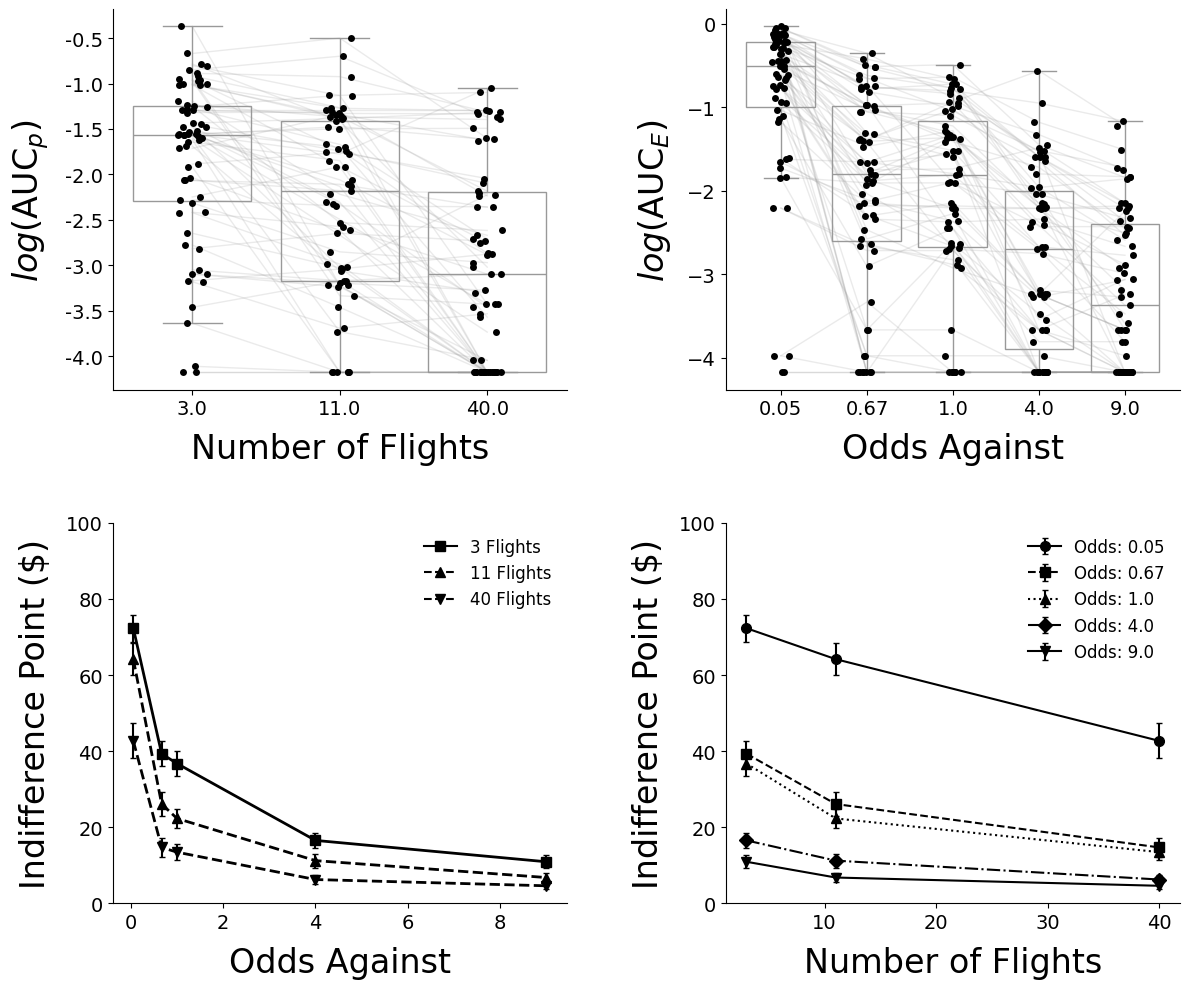

In [ ]:
# Add probability labels from odds against for plotting
auc_prob_df['probability'] = auc_prob_df['odds_against'].map(prob_odds_dict)

# Define marker and line styles per effort level
effort_styles = {
    0:  {'marker': 'o', 'facecolor': 'black', 'edgecolor': 'black', 'linestyle': '-',  'linecolor': 'black'},
    3:  {'marker': 's', 'facecolor': 'black', 'edgecolor': 'black', 'linestyle': '-',  'linecolor': 'black'},
    11: {'marker': '^', 'facecolor': 'black', 'edgecolor': 'black', 'linestyle': '--', 'linecolor': 'black'},
    40: {'marker': 'v', 'facecolor': 'black', 'edgecolor': 'black', 'linestyle': '--', 'linecolor': 'black'}
}

effort_levels = sorted(df['effort'].unique())
odds_levels = sorted(df['odds_against'].unique())

# Plot figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))


# Top-left: Effort AUC as a function of Effort (with within-subject lines)
ax = axes[0, 0]

x_vals = auc_eff_df['effort']
y_vals = np.log(auc_eff_df['auc_effort_as_func_prob'])

sns.boxplot(
    x=x_vals,
    y=y_vals,
    color=(1, 1, 1, 0.05),
    ax=ax,
    showfliers=False
)
sns.stripplot(
    x=x_vals,
    y=y_vals,
    color='k',
    ax=ax
)


# Within-subject spaghetti lines
tmp = auc_eff_df.copy()
tmp['x'] = tmp['effort']
tmp['y'] = np.log(tmp['auc_effort_as_func_prob'])

x_order = sorted(tmp['x'].unique())
x_pos = {x: i for i, x in enumerate(x_order)}
tmp['x_pos'] = tmp['x'].map(x_pos)

for pid, g in tmp.groupby('pid'):
    g = g.sort_values('x_pos')
    ax.plot(
        g['x_pos'], g['y'],
        color='0.6', linewidth=1, alpha=0.2, zorder=2
    )

ax.set_xticks(range(len(x_order)))
ax.set_xticklabels([str(x) for x in x_order])

ax.set_ylabel(r'$log$(AUC$_p$)', fontsize=24, labelpad=10)
ax.set_xlabel('Number of Flights', fontsize=24, labelpad=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y:.1f}'))
ax.tick_params(axis='both', labelsize=14)
sns.despine(ax=ax, top=True, right=True)


# Top-right: Prob AUC as a function of Odds Against (with within-subject lines)
ax = axes[0, 1]

# Base box + points
x_vals = auc_prob_df['odds_against'].round(2)
y_vals = np.log(auc_prob_df['auc_prob_as_func_effort'])

sns.boxplot(
    x=x_vals,
    y=y_vals,
    color=(1, 1, 1, 0.05),
    ax=ax,
    showfliers=False
)
sns.stripplot(
    x=x_vals,
    y=y_vals,
    color='k',
    ax=ax
)

# Within-subject spaghetti lines
tmp = auc_prob_df.copy()
tmp['x'] = tmp['odds_against'].round(2)
tmp['y'] = np.log(tmp['auc_prob_as_func_effort'])

x_order = sorted(tmp['x'].unique())
x_pos = {x: i for i, x in enumerate(x_order)}
tmp['x_pos'] = tmp['x'].map(x_pos)

for pid, g in tmp.groupby('pid'):
    g = g.sort_values('x_pos')
    ax.plot(
        g['x_pos'], g['y'],
        color='0.6', linewidth=1, alpha=0.2, zorder=2
    )

# Ensure ticks match the numeric odds labels
ax.set_xticks(range(len(x_order)))
ax.set_xticklabels([str(x) for x in x_order])

ax.set_ylabel(r'$log$(AUC$_E$)', fontsize=24, labelpad=10)
ax.set_xlabel('Odds Against', fontsize=24, labelpad=10)
ax.tick_params(axis='both', labelsize=14)
sns.despine(ax=ax, top=True, right=True)


# Bottom-left: Indiff as a function of Odds Against
ax = axes[1, 0]
legend_elements = []

for eff in effort_levels:
    temp_df = df[df['effort'] == eff]
    grouped = temp_df.groupby('odds_against')['indiff_point']

    odds_vals = grouped.mean().index.to_numpy()
    indiff_mean = grouped.mean().to_numpy()

    counts = grouped.count()
    sem = (grouped.std(ddof=1) / np.sqrt(counts)).fillna(0).to_numpy()

    # sort so lines connect in x-order
    order = np.argsort(odds_vals)
    odds_vals = odds_vals[order]
    indiff_mean = indiff_mean[order]
    sem = sem[order]

    style = effort_styles.get(
        eff,
        {'marker': 'o', 'facecolor': 'black', 'edgecolor': 'black', 'linestyle': '-', 'linecolor': 'black'}
    )

    ax.errorbar(
        odds_vals, indiff_mean, yerr=sem,
        fmt=style['marker'],
        markerfacecolor=style['facecolor'],
        markeredgecolor=style['edgecolor'],
        linestyle=style['linestyle'],
        color=style['linecolor'],
        ecolor=style['edgecolor'],
        capsize=2, elinewidth=1.5, markersize=7, linewidth=2
    )

    legend_elements.append(Line2D(
        [0], [0],
        marker=style['marker'],
        markerfacecolor=style['facecolor'],
        markeredgecolor=style['edgecolor'],
        linestyle=style['linestyle'],
        color=style['linecolor'],
        label=f"{int(eff)} Flights",
        markersize=7
    ))

ax.set_xlabel("Odds Against", fontsize=24, labelpad=10)
ax.set_ylabel("Indifference Point ($)", fontsize=24, labelpad=10)
ax.tick_params(axis='both', labelsize=14)
ax.set_ylim(0, 100)
ax.set_xscale('linear')
ax.legend(handles=legend_elements, frameon=False, fontsize=12)
sns.despine(ax=ax, top=True, right=True)


# Bottom-right: Indiff as a function of Effort
ax = axes[1, 1]
marker_shapes = ['o', 's', '^', 'D', 'v']
line_styles = ['-', '--', ':', '-.']
odds_styles = {
    odds: {
        'marker': marker_shapes[i % len(marker_shapes)],
        'facecolor': 'k',
        'edgecolor': 'black',
        'linestyle': line_styles[i % len(line_styles)],
        'linecolor': 'k'
    }
    for i, odds in enumerate(odds_levels)
}

for odds in odds_levels:
    temp_df = df[df['odds_against'] == odds]
    grouped = temp_df.groupby('effort')['indiff_point']

    effort_vals = grouped.mean().index.values
    indiff_mean = grouped.mean().values

    counts = grouped.count()
    sem = grouped.std(ddof=1) / np.sqrt(counts)

    style = odds_styles[odds]

    ax.errorbar(
        effort_vals, indiff_mean, yerr=sem,
        fmt=style['marker'],
        markerfacecolor=style['facecolor'],
        markeredgecolor=style['edgecolor'],
        linestyle=style['linestyle'],
        color=style['linecolor'],
        capsize=2, elinewidth=1.5, markersize=7,
        label=f"Odds: {round(odds, 2)}"
    )

ax.set_xlabel("Number of Flights", fontsize=24, labelpad=10)
ax.set_ylabel("Indifference Point ($)", fontsize=24, labelpad=10)
ax.tick_params(axis='both', labelsize=14)
ax.set_ylim(0, 100)
ax.set_xscale('linear')
ax.legend(frameon=False, fontsize=12)
sns.despine(ax=ax, top=True, right=True)

# Layout tweaks
plt.tight_layout()
plt.subplots_adjust(hspace=0.35, wspace=0.35)

# Run stats
print_friedman_and_posthoc(auc_eff_df, 'pid', 'effort', 'auc_effort_as_func_prob', 'Effort AUC')
print_friedman_and_posthoc(auc_prob_df, 'pid', 'odds_against', 'auc_prob_as_func_effort', 'Probability AUC')

plt.show()


## Combined Effects Models

Let:

- $O$ = odds against $= \dfrac{1-p}{p}$
- $p$ = probability of receiving the reward
- $E$ = effort (e.g., number of flights)
- $A$ = reward amount / undiscounted value scale parameter

---

## Hyperboloid models of probability and effort (MG and Rachlin forms)

### 1. MG$_p$–MG$_E$ Additive

$$
V(O,E)=\frac{A}{(1+hO)^{s_{prob}}+(1+\gamma E)^{s_{eff}}}
$$

### 2. MG$_p$–MG$_E$ Multiplicative

$$
V(O,E)=\frac{A}{(1+hO)^{s_{prob}}\cdot(1+\gamma E)^{s_{eff}}}
$$

---

### 3. R$_p$–R$_E$ Additive

$$
V(O,E)=\frac{A}{\left(1+hO^{s_{prob}}\right)+\left(1+\gamma E^{s_{eff}}\right)}
$$

### 4. R$_p$–R$_E$ Multiplicative

$$
V(O,E)=\frac{A}{\left(1+hO^{s_{prob}}\right)\cdot\left(1+\gamma E^{s_{eff}}\right)}
$$

---

## Probability discounting + Power-law effort term

Define the power-law effort denominator term:

$$
D_E(E)=1+k_E E^{s_{par}}
$$

### 5. MG$_p$–P$_E$ Additive

$$
V(O,E)=\frac{A}{(1+hO)^{s_{prob}}+\left(1+k_E E^{s_{par}}\right)}
$$

### 6. R$_p$–P$_E$ Additive

$$
V(O,E)=\frac{A}{\left(1+hO^{s_{prob}}\right)+\left(1+k_E E^{s_{par}}\right)}
$$

---

## Probability discounting + Multiplicative power-law effort factor

Define the multiplicative effort factor:

$$
F_E(E)=1-\gamma_e E^{s_e}
$$

### 7. MG$_p$–P$_E$ Multiplicative

$$
V(O,E)=\left(\frac{A}{(1+hO)^{s_{prob}}}\right)\cdot\left(1-\gamma_e E^{s_e}\right)
$$

### 8. R$_p$–P$_E$ Multiplicative

$$
V(O,E)=\left(\frac{A}{1+hO^{s_{prob}}}\right)\cdot\left(1-\gamma_e E^{s_e}\right)
$$

---

## GTD model combining probability and effort (probability weighting + effort cost)

### 9. GTD

$$
V(p,E)=\left[\max\left(0,\; A^{\alpha\, w(p)}-(k_EE)^{\beta}\right)\right]^{1/\alpha}
$$

### Prelec probability-weighting function

$$
w(p)=\exp\left(-\kappa\left(-\ln p\right)^{\gamma}\right)
$$

---

## Parameter meanings

### Probability discounting parameters (MG form)
- $h$: probability discounting rate parameter  
- $s_{prob}$: probability discounting curvature/exponent  

### Effort discounting parameters (hyperboloid effort term)
- $\gamma$: effort discounting rate parameter  
- $s_{eff}$: effort discounting curvature/exponent  

### Additive power-law effort term parameters
- $k_E$: effort scaling parameter  
- $s_{par}$: effort exponent  

### Multiplicative power-law effort factor parameters
- $\gamma_e$: effort scaling parameter in multiplicative factor  
- $s_e$: effort exponent in multiplicative factor  

### GTD parameters
- $\alpha$: curvature/scaling parameter  
- $\kappa, \gamma$: Prelec probability-weighting parameters  
- $k_E$: effort scaling parameter  
- $\beta$: effort-cost exponent  


In [ ]:
# AIC / AICc / BIC (Gaussian RSS form)
def _safe_sigma2_from_rss(rss: float, n: int, eps: float = 1e-12) -> float:
    return max(rss / max(n, 1), eps)

def compute_aic_from_rss(n: int, rss: float, k: int) -> float:
    sigma2 = _safe_sigma2_from_rss(rss, n)
    return n * np.log(sigma2) + 2 * k

def compute_aicc_from_rss(n: int, rss: float, k: int) -> float:
    aic = compute_aic_from_rss(n, rss, k)
    return aic + (2 * k * (k + 1)) / (n - k - 1) if n > (k + 1) else np.nan

def compute_bic_from_rss(n: int, rss: float, k: int) -> float:
    sigma2 = _safe_sigma2_from_rss(rss, n)
    return n * np.log(sigma2) + k * np.log(n)


# 1) Hyperboloid combined-effects models (MG + Rachlin)
def hyper_mg_prob(O, h, s_prob):
    return (1.0 + h * O) ** s_prob

def hyper_mg_eff(E, gamma, s_eff):
    return (1.0 + gamma * E) ** s_eff

def hyper_rach_prob(O, h, s_prob):
    return 1.0 + h * (O ** s_prob)

def hyper_rach_eff(E, gamma, s_eff):
    return 1.0 + gamma * (E ** s_eff)

def combined_mult(X, A, h, s_prob, gamma, s_eff, prob_form="mg", eff_form="mg"):
    O = X[:, 0]
    E = X[:, 1]
    Dp = hyper_mg_prob(O, h, s_prob) if prob_form == "mg" else hyper_rach_prob(O, h, s_prob)
    De = hyper_mg_eff(E, gamma, s_eff) if eff_form == "mg" else hyper_rach_eff(E, gamma, s_eff)
    return A / (Dp * De)

def combined_add(X, A, h, s_prob, gamma, s_eff, prob_form="mg", eff_form="mg"):
    O = X[:, 0]
    E = X[:, 1]
    Dp = hyper_mg_prob(O, h, s_prob) if prob_form == "mg" else hyper_rach_prob(O, h, s_prob)
    De = hyper_mg_eff(E, gamma, s_eff) if eff_form == "mg" else hyper_rach_eff(E, gamma, s_eff)
    return A / (Dp + De)

def mult_mg(X, A, h, s_prob, gamma, s_eff):
    return combined_mult(X, A, h, s_prob, gamma, s_eff, prob_form="mg", eff_form="mg")

def add_mg(X, A, h, s_prob, gamma, s_eff):
    return combined_add(X, A, h, s_prob, gamma, s_eff, prob_form="mg", eff_form="mg")

def mult_rach(X, A, h, s_prob, gamma, s_eff):
    return combined_mult(X, A, h, s_prob, gamma, s_eff, prob_form="rach", eff_form="rach")

def add_rach(X, A, h, s_prob, gamma, s_eff):
    return combined_add(X, A, h, s_prob, gamma, s_eff, prob_form="rach", eff_form="rach")


# 2) Probability discounting (MG/Rachlin) + Power-Law Effort

#     Additive interaction:
#       1 + kE * E^(s_par)
def denom_eff_power(E, kE, s_par):
    E = np.asarray(E, dtype=float)
    return 1.0 + kE * (E ** s_par)

def mgprob_x_power_add(X, A, h, s_prob, kE, s_par):
    O = X[:, 0]
    E = X[:, 1]
    return A / (hyper_mg_prob(O, h, s_prob) + denom_eff_power(E, kE, s_par))

def rachprob_x_power_add(X, A, h, s_prob, kE, s_par):
    O = X[:, 0]
    E = X[:, 1]
    return A / (hyper_rach_prob(O, h, s_prob) + denom_eff_power(E, kE, s_par))

#    Multiplicative interaction:
#      V = (A / Dp) * (1 - gamma * E^(s_e))

def mgprob_x_power_mult(X, A, h, s_prob, gamma_e, s_e):
    O = X[:, 0]
    E = X[:, 1]
    Dp = hyper_mg_prob(O, h, s_prob)
    eff_factor = 1.0 - gamma_e * (E ** s_e)
    return (A / Dp) * eff_factor

def rachprob_x_power_mult(X, A, h, s_prob, gamma_e, s_e):
    O = X[:, 0]
    E = X[:, 1]
    Dp = hyper_rach_prob(O, h, s_prob)
    eff_factor = 1.0 - gamma_e * (E ** s_e)
    return (A / Dp) * eff_factor


# 3) GTD probability + effort
def prelec_w(p, kappa, gamma):
    p = np.clip(p, 1e-12, 1.0)
    return np.exp(-kappa * ((-np.log(p)) ** gamma))

def gtd_prob_effort(X, A, alpha, kappa, gamma, kE, beta):
    p = X[:, 0]
    E = X[:, 1]
    w = prelec_w(p, kappa=kappa, gamma=gamma)
    inner = (A ** (alpha * w)) - ((kE * E) ** beta)
    inner = np.maximum(inner, 0.0)
    alpha = np.clip(alpha, 1e-8, None)
    return inner ** (1.0 / alpha)


In [ ]:
# Fit loop
records = []
part_failed = []
part_worked = []

for part in df["pid"].unique():
    part_df = (
        df[df["pid"] == part]
        .drop_duplicates(subset=["probability", "effort"], keep="last")
        .reset_index(drop=True)
        .copy()
    )

    try:
        p = part_df["probability"].values.astype(float)
        E = part_df["effort"].values.astype(float)
        Y = part_df["indiff_point"].values.astype(float)
        n = len(Y)
        if "odds_against" in part_df.columns:
            O = part_df["odds_against"].values.astype(float)
        else:
            if np.any(p <= 0) or np.any(p > 1):
                raise ValueError("probability must be in (0, 1].")
            O = (1.0 - p) / p

        if n < 5 or np.nanstd(Y) < 1e-8:
            print(f"n < 5 for participant {part}", f"\n{part_df}\n\n")
            continue
        if np.any(p <= 0) or np.any(p > 1):
            raise ValueError("probability must be in (0, 1].")

        X_OE = np.column_stack((O, E))
        X_pE = np.column_stack((p, E))
        A_init = float(np.nanmax(Y))

        def score_and_pack(pid, model_name, params, yhat):
            resid = (Y - yhat)
            rss = float(np.nansum(resid ** 2))
            mse = float(np.nanmean(resid ** 2))
            k = len(params)
            return {
                "pid": pid,
                "model": model_name,
                "r2": r2_score(Y, yhat),
                "mae": mean_absolute_error(Y, yhat),
                "mse": mse,
                "rss": rss,
                "aic": compute_aic_from_rss(n, rss, k),
                "aicc": compute_aicc_from_rss(n, rss, k),
                "bic": compute_bic_from_rss(n, rss, k),
                "n_obs": n,
                "effort_mean": float(np.nanmean(E)),
                "params": params,
            }

        # Hyperboloid combined models, additive or multiplicative
        p0_hyp = [A_init, 1.0, 1.0, 1.0, 1.0]
        lb_hyp = [1e-6, 1e-6, 1e-6, 1e-6, 1e-6]
        ub_hyp = [100.0, 50.0, 5.0, 50.0, 5.0]

        hyp_models = [
            ("hyper_mult_mg",   mult_mg),
            ("hyper_add_mg",    add_mg),
            ("hyper_mult_rach", mult_rach),
            ("hyper_add_rach",  add_rach),
        ]

        for name, fn in hyp_models:
            params, _ = curve_fit(fn, X_OE, Y, p0=p0_hyp, bounds=(lb_hyp, ub_hyp), maxfev=60000)
            yhat = fn(X_OE, *params)
            rec = score_and_pack(part, name, params, yhat)
            rec.update({"A": params[0], "h": params[1], "s_prob": params[2], "gamma_eff": params[3], "s_eff": params[4]})
            records.append(rec)

        # R or GM Prob + power-law effort
        p0_par = [A_init, 1.0, 1.0, 0.01, 2.0]
        lb_par = [1e-6, 1e-6, 1e-6, 1e-9, 0.25]
        ub_par = [100.0, 50.0, 5.0, 10.0, 6.0]

        par_models = [
            ("mgprob_x_power_mult",   mgprob_x_power_mult),
            ("mgprob_x_power_add",    mgprob_x_power_add),
            ("rachprob_x_power_mult", rachprob_x_power_mult),
            ("rachprob_x_power_add",  rachprob_x_power_add),
        ]

        for name, fn in par_models:
            params, _ = curve_fit(fn, X_OE, Y, p0=p0_par, bounds=(lb_par, ub_par), maxfev=80000)
            yhat = fn(X_OE, *params)
            rec = score_and_pack(part, name, params, yhat)
            rec.update({"A": params[0], "h": params[1], "s_prob": params[2], "kE": params[3], "s_par": params[4]})
            records.append(rec)

        # General Theory of Discounting
        p0_gtd = [A_init, 0.5, 0.3, 0.8, 0.1, 0.5]
        lb_gtd = [1e-6, 1e-4, 1e-6, 1e-3, 1e-6, 1e-3]
        ub_gtd = [100.0, 5.0,  10.0,  5.0,  10.0,  5.0]

        params, _ = curve_fit(gtd_prob_effort, X_pE, Y, p0=p0_gtd, bounds=(lb_gtd, ub_gtd), maxfev=120000)
        yhat = gtd_prob_effort(X_pE, *params)
        rec = score_and_pack(part, "gtd_prob_effort", params, yhat)
        rec.update({"A": params[0], "alpha": params[1], "kappa": params[2], "gamma": params[3], "kE": params[4], "beta": params[5]})
        records.append(rec)

    except Exception as e:
        print(f"Fit failed for {part}: {e}")
        part_failed.append([part, e])
        continue

results_df = pd.DataFrame(records)

n < 5 for participant P3 
   pid     question                                             choice  \
0   P3   95_3_$3.10  100% Chance of Getting $3.10 without climbing ...   
1   P3   60_3_$3.10  100% Chance of Getting $3.10 without climbing ...   
2   P3   50_3_$3.10  100% Chance of Getting $3.10 without climbing ...   
3   P3   20_3_$3.10  100% Chance of Getting $3.10 without climbing ...   
4   P3   10_3_$3.10  100% Chance of Getting $3.10 without climbing ...   
5   P3  95_11_$3.10  100% Chance of Getting $3.10 without climbing ...   
6   P3  60_11_$3.10  100% Chance of Getting $3.10 without climbing ...   
7   P3  50_11_$3.10  100% Chance of Getting $3.10 without climbing ...   
8   P3  20_11_$3.10  100% Chance of Getting $3.10 without climbing ...   
9   P3  10_11_$3.10  100% Chance of Getting $3.10 without climbing ...   
10  P3  95_40_$3.10  100% Chance of Getting $3.10 without climbing ...   
11  P3  60_40_$3.10  100% Chance of Getting $3.10 without climbing ...   
12  P3  50_4

/tmp/ipykernel_7866/1676894959.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_7866/1676894959.py:73: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_7866/1676894959.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_7866/1676894959.py:123: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')



=== AICc ===
Friedman test statistic: 253.268, p-value: 0.00000
Post-hoc Wilcoxon tests with Bonferroni correction:
  gtd_prob_effort vs. hyper_add_mg: W=83.00000, corrected p = 0.00000 *
  gtd_prob_effort vs. hyper_add_rach: W=119.00000, corrected p = 0.00000 *
  gtd_prob_effort vs. hyper_mult_mg: W=685.00000, corrected p = 1.00000 n.s.
  gtd_prob_effort vs. hyper_mult_rach: W=786.00000, corrected p = 1.00000 n.s.
  gtd_prob_effort vs. mgprob_x_power_add: W=97.00000, corrected p = 0.00000 *
  gtd_prob_effort vs. mgprob_x_power_mult: W=843.00000, corrected p = 1.00000 n.s.
  gtd_prob_effort vs. rachprob_x_power_add: W=122.00000, corrected p = 0.00000 *
  gtd_prob_effort vs. rachprob_x_power_mult: W=892.00000, corrected p = 1.00000 n.s.
  hyper_add_mg vs. hyper_add_rach: W=35.00000, corrected p = 0.00000 *
  hyper_add_mg vs. hyper_mult_mg: W=20.00000, corrected p = 0.00000 *
  hyper_add_mg vs. hyper_mult_rach: W=8.00000, corrected p = 0.00000 *
  hyper_add_mg vs. mgprob_x_power_add: W=

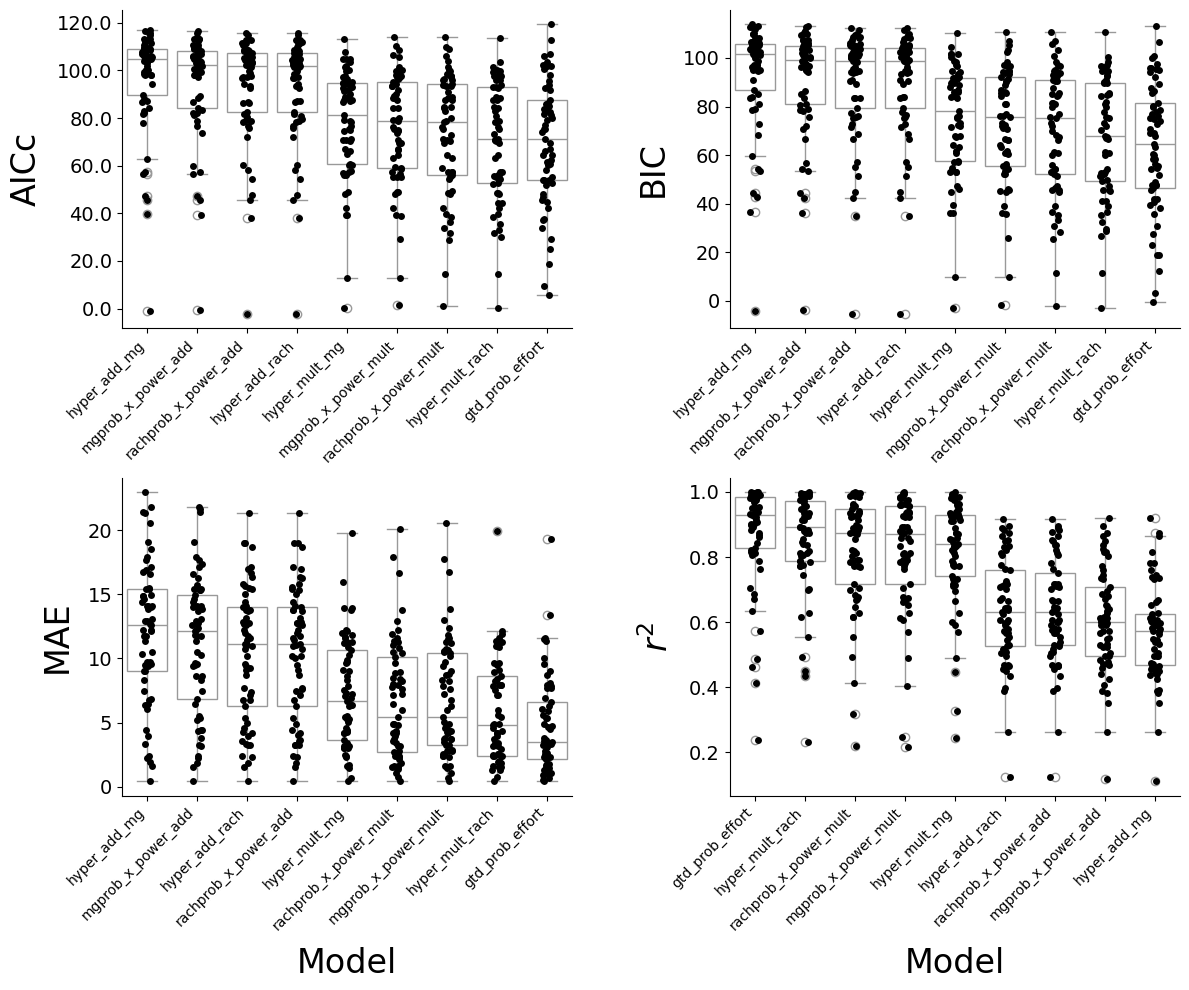

In [ ]:
# Compute per-panel model order
# Highest -> Lowest along x-axis within each plot
order_aicc = (results_df.groupby('model')['aicc']
              .median()
              .sort_values(ascending=False)
              .index)

order_bic  = (results_df.groupby('model')['bic']
              .median()
              .sort_values(ascending=False)
              .index)

order_mae  = (results_df.groupby('model')['mae']
              .median()
              .sort_values(ascending=False)
              .index)

order_r2   = (results_df.groupby('model')['r2']
              .median()
              .sort_values(ascending=False)
              .index)

# Plot figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Top-left: AICc
ax = axes[0, 0]
sns.boxplot(
    x='model',
    y='aicc',
    data=results_df,
    order=order_aicc,
    color='w',
    ax=ax
)
sns.stripplot(
    x='model',
    y='aicc',
    data=results_df,
    order=order_aicc,
    color='k',
    ax=ax
)
ax.set_ylabel('AICc', fontsize=24, labelpad=10)
ax.set_xlabel('Model', fontsize=24, labelpad=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y:.1f}'))
ax.tick_params(axis='y', labelsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.tick_params(axis='x', labelsize=10)
sns.despine(ax=ax, top=True, right=True)

# Top-right: BIC
ax = axes[0, 1]
sns.boxplot(
    x='model',
    y='bic',
    data=results_df,
    order=order_bic,
    color='w',
    ax=ax
)
sns.stripplot(
    x='model',
    y='bic',
    data=results_df,
    order=order_bic,
    color='k',
    ax=ax
)
ax.set_ylabel('BIC', fontsize=24, labelpad=10)
ax.set_xlabel('Model', fontsize=24, labelpad=10)
ax.tick_params(axis='y', labelsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.tick_params(axis='x', labelsize=10)
sns.despine(ax=ax, top=True, right=True)

# Bottom-left: MAE
ax = axes[1, 0]
sns.boxplot(
    x='model',
    y='mae',
    data=results_df,
    order=order_mae,
    color='w',
    ax=ax
)
sns.stripplot(
    x='model',
    y='mae',
    data=results_df,
    order=order_mae,
    color='k',
    ax=ax
)
ax.set_ylabel('MAE', fontsize=24, labelpad=10)
ax.set_xlabel('Model', fontsize=24, labelpad=10)
ax.tick_params(axis='y', labelsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.tick_params(axis='x', labelsize=10)
sns.despine(ax=ax, top=True, right=True)

# Bottom-right: r^2
ax = axes[1, 1]
sns.boxplot(
    x='model',
    y='r2',
    data=results_df,
    order=order_r2,
    color='w',
    ax=ax
)
sns.stripplot(
    x='model',
    y='r2',
    data=results_df,
    order=order_r2,
    color='k',
    ax=ax
)
ax.set_ylabel(r'$r^2$', fontsize=24, labelpad=10)
ax.set_xlabel('Model', fontsize=24, labelpad=10)
ax.tick_params(axis='y', labelsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.tick_params(axis='x', labelsize=10)
sns.despine(ax=ax, top=True, right=True)

# Layout tweaks
plt.tight_layout()
plt.subplots_adjust(hspace=0.47, wspace=0.35)

# Run stats
print_friedman_and_posthoc(results_df, 'pid', 'model', 'aicc', 'AICc')
print_friedman_and_posthoc(results_df, 'pid', 'model', 'mae', 'MAE')

plt.show()

In [ ]:
# Identify best model per PID by minimum AICc (across ALL models)
EPS = 1e-12

# Ensure key metric columns are numeric
metric_cols = ["mse", "aic", "aicc", "bic", "r2", "mae", "n_obs", "effort_mean"]
for c in metric_cols:
    if c in results_df.columns:
        results_df[c] = pd.to_numeric(results_df[c], errors="coerce")

# Guard MSE <= 0 (can create +/-inf AIC/BIC)
if "mse" in results_df.columns:
    results_df.loc[results_df["mse"] <= 0, "mse"] = EPS

# Drop rows without AICc (cannot rank those) + drop non-finite AICc
df_rank = results_df.dropna(subset=["aicc"]).copy()
df_rank = df_rank[np.isfinite(df_rank["aicc"])].copy()

# Verify same n_obs across models within each pid
if "n_obs" in df_rank.columns:
    nobs_check = df_rank.groupby("pid")["n_obs"].nunique()
    bad_pids = nobs_check[nobs_check > 1].index.tolist()
    if len(bad_pids) > 0:
        print(f"Warning: {len(bad_pids)} PIDs have differing n_obs across models (AICc comparability issue).")

# Compute delta AICc within pid (AICc - best AICc for that pid)
df_rank["best_aicc_pid"] = df_rank.groupby("pid")["aicc"].transform("min")
df_rank["delta_aicc"] = df_rank["aicc"] - df_rank["best_aicc_pid"]

# Akaike weights within pid
def _akaike_weights(delta_series: pd.Series) -> pd.Series:
    d = delta_series.to_numpy(dtype=float)
    w = np.exp(-0.5 * d)
    s = np.nansum(w)
    if s == 0 or np.isnan(s):
        return pd.Series([np.nan] * len(delta_series), index=delta_series.index)
    return pd.Series(w / s, index=delta_series.index)

df_rank["akaike_w"] = df_rank.groupby("pid")["delta_aicc"].transform(_akaike_weights)

# Pick the best model per pid (tie-breaker: lower BIC, then higher R2)
sort_cols = ["pid", "aicc"]
sort_asc  = [True, True]
if "bic" in df_rank.columns:
    sort_cols.append("bic")
    sort_asc.append(True)
if "r2" in df_rank.columns:
    sort_cols.append("r2")
    sort_asc.append(False)

df_rank_sorted = df_rank.sort_values(by=sort_cols, ascending=sort_asc)

best_cols = ["pid", "model", "aicc", "bic", "aic", "r2", "mae", "delta_aicc", "akaike_w", "n_obs", "effort_mean"]
best_cols = [c for c in best_cols if c in df_rank_sorted.columns]

best_by_pid = (
    df_rank_sorted.groupby("pid", as_index=False)
    .head(1)
    .loc[:, best_cols]
    .rename(columns={"model": "best_model", "aicc": "best_aicc"})
    .reset_index(drop=True)
)

# Create wide “scoreboards” per pid (AICc / delta / weight)
aicc_wide  = df_rank.pivot_table(index="pid", columns="model", values="aicc", aggfunc="first")
delta_wide = df_rank.pivot_table(index="pid", columns="model", values="delta_aicc", aggfunc="first")
w_wide     = df_rank.pivot_table(index="pid", columns="model", values="akaike_w", aggfunc="first")

# Add a leftmost quick-glance column naming the lowest-AICc model
aicc_wide.insert(
    0,
    "best_model_by_aicc",
    aicc_wide.idxmin(axis=1)
)

# Enforce consistent column order
model_order = [
    'hyper_mult_mg', 'hyper_add_mg',
    'hyper_mult_rach', 'hyper_add_rach',
    'mgprob_x_power_mult', 'mgprob_x_power_add',
    'rachprob_x_power_mult', 'rachprob_x_power_add',
    'gtd_prob_effort'
]

# Keep only models present
keep_models = [m for m in model_order if m in aicc_wide.columns]

# Reindex scoreboards
aicc_wide  = aicc_wide.reindex(columns=["best_model_by_aicc"] + keep_models)
delta_wide = delta_wide.reindex(columns=keep_models)
w_wide     = w_wide.reindex(columns=keep_models)

# Quick views
print("Best model by PID (top 10 by best AICc):")
print(best_by_pid.sort_values("best_aicc").head(10))

print("\nModel counts (how often each wins):")
print(best_by_pid["best_model"].value_counts(dropna=False))

Best model by PID (top 10 by best AICc):
    pid             best_model  best_aicc        bic        aic        r2  \
48  P54   rachprob_x_power_add  -2.106840  -5.233256  -8.773507  0.527723   
34  P41        gtd_prob_effort   9.679783   3.428085  -0.820217  0.999532   
57  P62        gtd_prob_effort  18.622725  12.371026   8.122725  0.999104   
49  P55        gtd_prob_effort  25.114886  18.863187  14.614886  0.998737   
46  P52  rachprob_x_power_mult  28.758004  25.631589  22.091338  0.997838   
44  P50        gtd_prob_effort  29.371498  23.119799  18.871498  0.997555   
16  P24        hyper_mult_rach  31.781814  28.655398  25.115147  0.993874   
1    P1        gtd_prob_effort  37.416002  18.803373  16.416002  0.997772   
13  P21   rachprob_x_power_add  38.198230  35.071814  31.531563  0.625950   
23  P31    mgprob_x_power_mult  39.438541  36.312125  32.771874  0.994930   

         mae  delta_aicc  akaike_w  n_obs  effort_mean  
48  0.435818         0.0  0.240840     15    18.000000

In [ ]:
# Save the wide dfs
aicc_wide.to_csv("aicc_wide.csv")
delta_wide.to_csv("delta_wide.csv")
w_wide.to_csv("w_wide.csv")

<>:281: SyntaxWarning: invalid escape sequence '\$'
<>:281: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_7866/3778801336.py:281: SyntaxWarning: invalid escape sequence '\$'
  f"MAE=\${fs['mae']:.2f}"


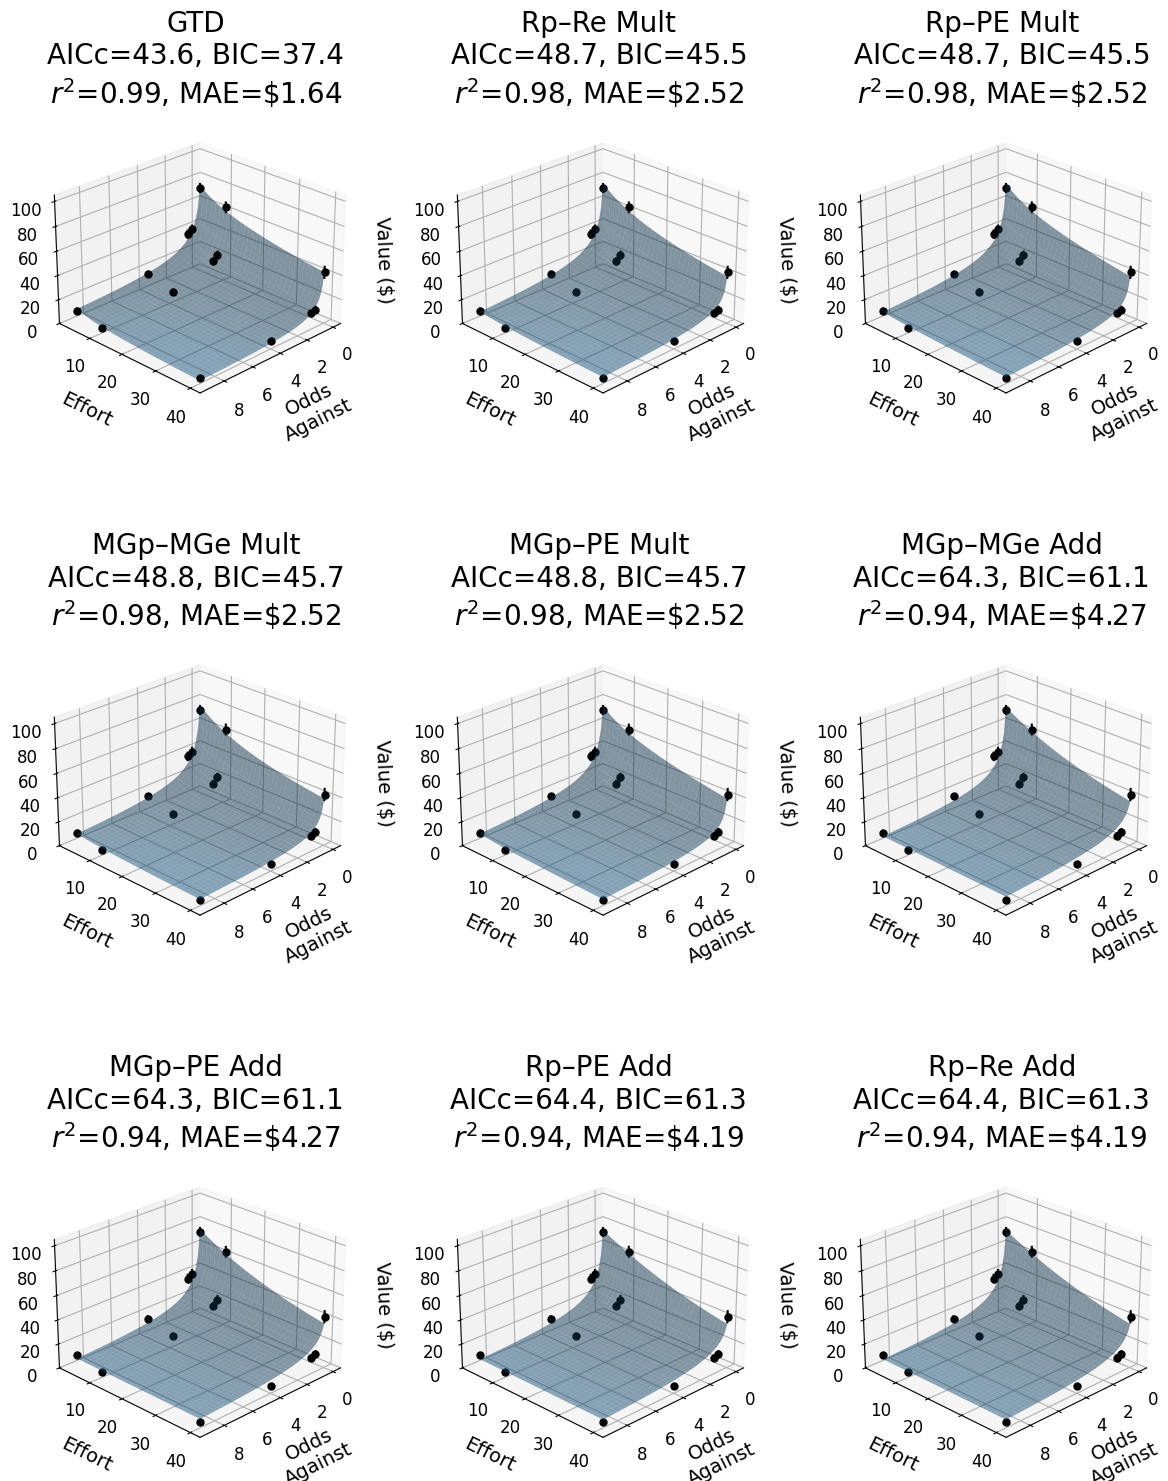

In [ ]:
# Group means + SEM
df_plot = df.copy()
grouped_df = (
    df_plot.groupby(["effort", "odds_against", 'probability'], as_index=False)["indiff_point"]
           .agg(indiff_point_mean="mean", indiff_point_sem="sem")
)
grouped_df["indiff_point_sem"] = grouped_df["indiff_point_sem"].fillna(0.0)

O = grouped_df["odds_against"].to_numpy(dtype=float)
E = grouped_df["effort"].to_numpy(dtype=float)
p = grouped_df["probability"].to_numpy(dtype=float)
Y = grouped_df["indiff_point_mean"].to_numpy(dtype=float)
Y_sem = grouped_df["indiff_point_sem"].to_numpy(dtype=float)

X_OE = np.column_stack([O, E])
p_from_O = np.column_stack([p, E])
X_pE = np.column_stack([p_from_O, E])

# Mesh for plotting (axes always in O/E)
odds_grid = np.linspace(np.nanmin(O), np.nanmax(O), 60)
eff_grid  = np.linspace(np.nanmin(E), np.nanmax(E), 60)
O_mesh, E_mesh = np.meshgrid(odds_grid, eff_grid)

X_mesh_OE = np.column_stack([O_mesh.ravel(), E_mesh.ravel()])
p_mesh    = 1.0 / (1.0 + O_mesh)
X_mesh_pE = np.column_stack([p_mesh.ravel(), E_mesh.ravel()])


# Small wrappers to reuse earlier model primitives
def _wrap_combined_mult(prob_form: str, eff_form: str):
    def f(X, A, h, s_prob, gamma, s_eff):
        return combined_mult(X, A, h, s_prob, gamma, s_eff,
                             prob_form=prob_form, eff_form=eff_form)
    return f

def _wrap_combined_add(prob_form: str, eff_form: str):
    def f(X, A, h, s_prob, gamma, s_eff):
        return combined_add(X, A, h, s_prob, gamma, s_eff,
                            prob_form=prob_form, eff_form=eff_form)
    return f

# Unified model registry: (name, fn, xtype, param_names)
#   xtype = "OE" uses X[:,0]=odds_against, X[:,1]=effort
#   xtype = "pE" uses X[:,0]=p,          X[:,1]=effort
models = [
    ("MGp–MGe Add",   _wrap_combined_add("mg",   "mg"),   "OE", ["A","h","s_prob","gamma","s_eff"]),
    ("MGp–MGe Mult",  _wrap_combined_mult("mg",  "mg"),   "OE", ["A","h","s_prob","gamma","s_eff"]),
    ("Rp–Re Add",     _wrap_combined_add("rach", "rach"), "OE", ["A","h","s_prob","gamma","s_eff"]),
    ("Rp–Re Mult",    _wrap_combined_mult("rach","rach"), "OE", ["A","h","s_prob","gamma","s_eff"]),

    ("MGp–PE Add",    mgprob_x_power_add,  "OE", ["A","h","s_prob","kE","s_par"]),
    ("Rp–PE Add",     rachprob_x_power_add,"OE", ["A","h","s_prob","kE","s_par"]),

    ("MGp–PE Mult",   mgprob_x_power_mult, "OE", ["A","h","s_prob","gamma_e","s_e"]),
    ("Rp–PE Mult",    rachprob_x_power_mult,"OE",["A","h","s_prob","gamma_e","s_e"]),

    ("GTD",           gtd_prob_effort,     "pE", ["A","alpha","kappa","gamma","kE","beta"]),
]



# Starts + bounds
A_init = float(np.nanmax(Y))

A_bounds      = (1e-6, 200.0)
h_bounds      = (1e-6, 50.0)
sprob_bounds  = (1e-3, 6.0)
gamma_bounds  = (1e-6, 50.0)
seff_bounds   = (1e-3, 6.0)

kE_bounds     = (1e-9, 50.0)
spar_bounds   = (0.25, 6.0)

gamma_e_bounds = (0.0, 1.0)
s_e_bounds     = (0.25, 6.0)

alpha_bounds   = (1e-3, 5.0)
kappa_bounds   = (1e-6, 10.0)
g_prelec_bounds= (1e-3, 5.0)
kE_gtd_bounds  = (1e-6, 10.0)
beta_bounds    = (1e-3, 5.0)

bounds_by_param = {
    "A":       A_bounds,
    "h":       h_bounds,
    "s_prob":  sprob_bounds,
    "gamma":   gamma_bounds,
    "s_eff":   seff_bounds,
    "kE":      kE_bounds,
    "s_par":   spar_bounds,
    "gamma_e": gamma_e_bounds,
    "s_e":     s_e_bounds,
    "alpha":   alpha_bounds,
    "kappa":   kappa_bounds,
    "gammaP":  g_prelec_bounds,
    "beta":    beta_bounds,
}

# Start guesses
p0_by_param = {
    "A":       A_init,
    "h":       1.0,
    "s_prob":  1.0,
    "gamma":   1.0,
    "s_eff":   1.0,
    "kE":      0.01,
    "s_par":   2.0,
    "gamma_e": 0.001,
    "s_e":     2.0,
    "alpha":   0.5,
    "kappa":   0.3,
    "gammaP":  0.8,
    "beta":    0.5,
}

def get_p0_and_bounds_from_param_list(param_names):
    p0 = []
    lb = []
    ub = []
    for p in param_names:
        if p == "gamma":
            if "alpha" in param_names and "kappa" in param_names:
                lo, hi = g_prelec_bounds
                p0.append(p0_by_param["gammaP"])
            else:
                lo, hi = gamma_bounds
                p0.append(p0_by_param["gamma"])
        elif p == "kE" and ("alpha" in param_names and "kappa" in param_names):
            lo, hi = kE_gtd_bounds
            p0.append(0.1)
        else:
            lo, hi = bounds_by_param[p]
            p0.append(p0_by_param[p])
        lb.append(lo)
        ub.append(hi)
    return p0, (lb, ub)


# Fit ALL models, compute AIC/AICc/BIC, sort by AICc
fit_summaries = []
n = int(len(Y))

for mname, mfn, xtype, param_names in models:
    X_fit = X_OE if xtype == "OE" else X_pE
    p0, bounds = get_p0_and_bounds_from_param_list(param_names)

    try:
        params, _ = curve_fit(
            mfn, X_fit, Y,
            p0=p0,
            bounds=bounds,
            maxfev=200000
        )

        Yhat = mfn(X_fit, *params)
        resid = (Y - Yhat)
        rss = float(np.nansum(resid ** 2))
        k = int(len(params))

        fit_summaries.append({
            "name": mname,
            "fn": mfn,
            "xtype": xtype,
            "param_names": param_names,
            "params": params,
            "r2": float(r2_score(Y, Yhat)),
            "mae": float(mean_absolute_error(Y, Yhat)),
            "rss": rss,
            "aicc": float(compute_aicc_from_rss(n, rss, k)),
            "bic": float(compute_bic_from_rss(n, rss, k)),
            "aic": float(compute_aic_from_rss(n, rss, k)),
        })

    except Exception as e:
        fit_summaries.append({
            "name": mname,
            "fn": mfn,
            "xtype": xtype,
            "param_names": param_names,
            "params": None,
            "r2": np.nan,
            "mae": np.nan,
            "rss": np.nan,
            "aicc": np.inf,
            "bic": np.inf,
            "aic": np.inf,
            "error": str(e),
        })

fit_summaries = sorted(fit_summaries, key=lambda d: d["aicc"])


# Plot in sorted order (top-left to bottom-right)
fig = plt.figure(figsize=(12, 16))

fig.subplots_adjust(
    left=0.05,
    right=0.98,
    bottom=0.05,
    top=0.95,
    hspace=0.32,   # vertical spacing between rows
    wspace=0.3    # horizontal spacing
)

ELEV = 25
AZIM = 45
SURF_ALPHA = 0.5

for i, fs in enumerate(fit_summaries, start=1):

    ax = fig.add_subplot(3, 3, i, projection="3d")

    mname  = fs["name"]
    xtype  = fs["xtype"]
    mfn    = fs["fn"]
    params = fs["params"]

    # Labels
    ax.set_xlabel("Odds\nAgainst", labelpad=10, fontsize=14)
    ax.set_ylabel("Effort", labelpad=10, fontsize=14)
    ax.set_zlabel("Value ($)", labelpad=10, fontsize=14)

    # Slightly shorter z aspect to reduce row overlap
    ax.set_box_aspect((1, 1, 0.7))

    ax.view_init(elev=ELEV, azim=AZIM)

    ax.set_zlim(0, max(105, np.nanmax(Y) * 1.05))

    # Data points
    ax.scatter(
        O,
        E,
        Y,
        c="k",
        s=25,
        depthshade=False
    )

    # SEM bars
    for x_, y_, z_, sem_ in zip(O, E, Y, Y_sem):
        if sem_ > 0:
            ax.plot(
                [x_, x_],
                [y_, y_],
                [z_ - sem_, z_ + sem_],
                c="k",
                linewidth=1.5
            )

    # Surface
    if params is not None:
        if xtype == "OE":
            Z = mfn(
                X_mesh_OE,
                *params
            ).reshape(O_mesh.shape)
        else:
            Z = mfn(
                X_mesh_pE,
                *params
            ).reshape(O_mesh.shape)
        Z = np.where(
            np.isfinite(Z),
            Z,
            np.nan
        )
        ax.plot_surface(
            O_mesh,
            E_mesh,
            Z,
            alpha=SURF_ALPHA,
            linewidth=0,
            antialiased=True
        )
        title = (
            f"{mname}\n"
            f"AICc={fs['aicc']:.1f}, "
            f"BIC={fs['bic']:.1f}\n"
            f"$r^2$={fs['r2']:.2f}, "
            f"MAE=\${fs['mae']:.2f}"
        )
    else:
        title = f"{mname}\nFIT FAILED"

    # IMPORTANT:
    # positive padding keeps titles attached to correct subplot
    ax.set_title(
        title,
        fontsize=20,
        pad=-20
    )
    ax.title.set_y(0.92)

    # Tick label size
    ax.tick_params(
        axis='both',
        which='major',
        labelsize=12
    )

plt.savefig(
    "model_surfaces.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.3
)

plt.show()

In [ ]:
# Build Table with results
model_order = [
    "hyper_mult_mg",
    "hyper_add_mg",
    "hyper_mult_rach",
    "hyper_add_rach",
    "mgprob_x_power_mult",
    "mgprob_x_power_add",
    "rachprob_x_power_mult",
    "rachprob_x_power_add",
    "gtd_prob_effort",
]

# Keep only models present in df_rank
models_present = set(df_rank["model"].unique())
models = [m for m in model_order if m in models_present]

# Ensure numeric
for c in ["aic", "aicc", "bic", "r2", "mae"]:
    if c in df_rank.columns:
        df_rank[c] = pd.to_numeric(df_rank[c], errors="coerce")

# Pivot metrics wide: columns like "r2 hyper_mult_mg", etc.
metrics = ["aicc", "bic", "mae", "r2"]
wide = (
    df_rank[df_rank["model"].isin(models)]
    .pivot_table(index="pid", columns="model", values=metrics, aggfunc="first")
)

# Flatten MultiIndex columns -> "r2 hyper_mult_mg"
wide.columns = [f"{metric} {model}" for metric, model in wide.columns]
wide = wide.reset_index()

# Best model among included models (min AICc)
aicc_cols = [f"aicc {m}" for m in models if f"aicc {m}" in wide.columns]
wide["Best Model"] = wide[aicc_cols].idxmin(axis=1).str.replace("aicc ", "", regex=False)
wide["Best AICc"] = wide[aicc_cols].min(axis=1)

# Difference in AICc relative to best per PID
for m in models:
    col = f"aicc {m}"
    if col in wide.columns:
        wide[f"delta-AICc {m}"] = wide[col] - wide["Best AICc"]

# Column ordering: PID, then metrics grouped by model, then Best Model, then ΔAICc block
ordered_cols = ["pid"]

# metric blocks per model (r2, mae, aicc, bic)
for metric in ["r2", "mae", "aicc", "bic"]:
    for m in models:
        col = f"{metric} {m}"
        if col in wide.columns:
            ordered_cols.append(col)

ordered_cols += ["Best Model", "Best AICc"]

# Deltas at the end
for m in models:
    col = f"delta-AICc {m}"
    if col in wide.columns:
        ordered_cols.append(col)

table_df = wide[ordered_cols].copy()

# Round for presentation
round_map = {}
for m in models:
    if f"r2 {m}" in table_df.columns:
        round_map[f"r2 {m}"] = 2
    if f"mae {m}" in table_df.columns:
        round_map[f"mae {m}"] = 2
    if f"aicc {m}" in table_df.columns:
        round_map[f"aicc {m}"] = 2
    if f"bic {m}" in table_df.columns:
        round_map[f"bic {m}"] = 2

if "Best AICc" in table_df.columns:
    round_map["Best AICc"] = 2

table_df = table_df.round(round_map)

# Export / view
table_df.to_csv("model_comparison_table.csv", index=False)
